# 04 - Hospitals, fire stations, candidate staging posts
**Input:** `data/raw/nys_hospitals_nyc.csv`, `data/raw/fdny_firehouses.csv`, zone boundaries from notebook 03
**Output:** `data/interim/hospitals.csv`, `data/interim/firehouses.csv`, `data/interim/candidate_posts.csv`

Hospitals are the transport destinations in the simulator. Hospital lots and firehouses are the candidate staging
posts for the relocation optimizer. (True ambulance station locations are not public -> state this assumption.)

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "README.md").exists())
sys.path.insert(0, str(ROOT / "src"))
RAW, INTERIM, PROCESSED = ROOT / "data/raw", ROOT / "data/interim", ROOT / "data/processed"
NB_DATA = ROOT / "notebooks/data"
INTERIM.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)

In [2]:
from grease.data.geo import load_geojson, locate

hosp = pd.read_csv(RAW / "nys_hospitals_nyc.csv", dtype={"fac_zip": str})
print(hosp.description.value_counts().to_dict())
hosp = hosp[hosp.description == "Hospital"]                     # drop 'Hospital Extension Clinic' rows
hosp = hosp.assign(lat=pd.to_numeric(hosp.latitude, errors="coerce"), lon=pd.to_numeric(hosp.longitude, errors="coerce"))
print("missing coords:", int(hosp.lat.isna().sum()))
hosp = hosp.dropna(subset=["lat", "lon"])
hosp = hosp[hosp.lat.between(40.45, 40.95) & hosp.lon.between(-74.30, -73.65)]   # NYC bounding box
hosp = hosp.drop_duplicates(["facility_name"])[["fac_id", "facility_name", "address1", "county", "fac_zip", "lat", "lon"]]
hosp = hosp.rename(columns={"facility_name": "name", "fac_zip": "zipcode"})
print(len(hosp), "hospitals"); hosp.head()

{'Hospital Extension Clinic': 240, 'Hospital': 68}
missing coords: 1
60 hospitals


,fac_id,name,address1,county,zipcode,lat,lon
7,1437,New York-Presbyterian/Lower Manhattan Hospital,170 William Street,New York,10038,40.710426,-74.005486
11,1165,Jacobi Medical Center,1400 Pelham Parkway,Bronx,10461,40.857388,-73.846741
17,1309,Interfaith Medical Center,1545 Atlantic Avenue,Kings,11213,40.677940,-73.937515
22,15437,Mount Sinai - Behavioral Health Center,45 Rivington Street,New York,10002,40.720820,-73.991090
30,1628,Flushing Hospital Medical Center,45th Avenue & Parsons Blvd,Queens,11355,40.755531,-73.815475


In [3]:
fh = pd.read_csv(RAW / "fdny_firehouses.csv", dtype={"postcode": str})
fh = fh.assign(lat=pd.to_numeric(fh.latitude, errors="coerce"), lon=pd.to_numeric(fh.longitude, errors="coerce")).dropna(subset=["lat", "lon"])
fh = fh[fh.lat.between(40.45, 40.95) & fh.lon.between(-74.30, -73.65)].rename(columns={"facilityname": "name", "postcode": "zipcode"})
fh["borough"] = fh.borough.str.upper()
print(len(fh), "firehouses"); fh.borough.value_counts()

219 firehouses


borough
BROOKLYN         66
QUEENS           51
MANHATTAN        48
BRONX            34
STATEN ISLAND    20
Name: count, dtype: int64

## Assign each facility to a zone (point-in-polygon)

In [4]:
mod = load_geojson(RAW / "modzcta_boundaries.geojson")
for d in (hosp, fh):
    d["zone"] = [locate(lo, la, mod, "modzcta") for lo, la in zip(d.lon, d.lat)]
print("unassigned hospitals:", int(hosp.zone.isna().sum()), "| firehouses:", int(fh.zone.isna().sum()))
hosp["borough"] = hosp.county.map({"New York": "MANHATTAN", "Kings": "BROOKLYN", "Queens": "QUEENS", "Bronx": "BRONX", "Richmond": "STATEN ISLAND"})

posts = pd.concat([
    hosp.assign(post_type="hospital")[["name", "post_type", "borough", "zone", "lat", "lon"]],
    fh.assign(post_type="firehouse")[["name", "post_type", "borough", "zone", "lat", "lon"]],
], ignore_index=True)
posts.insert(0, "post_id", range(len(posts)))
print(posts.groupby(["borough", "post_type"]).size().unstack(fill_value=0))
hosp.to_csv(INTERIM / "hospitals.csv", index=False); fh.to_csv(INTERIM / "firehouses.csv", index=False); posts.to_csv(INTERIM / "candidate_posts.csv", index=False)

unassigned hospitals: 0 | firehouses: 2
post_type      firehouse  hospital
borough                           
BRONX                 34        10
BROOKLYN              66        16
MANHATTAN             48        21
QUEENS                51         9
STATEN ISLAND         20         4


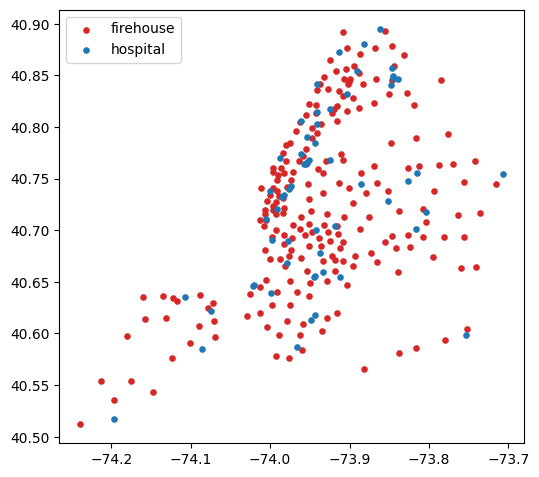

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
for t, c in [("firehouse", "tab:red"), ("hospital", "tab:blue")]:
    s = posts[posts.post_type == t]; ax.scatter(s.lon, s.lat, s=14, c=c, label=t)
ax.legend(); ax.set_aspect(1.3); plt.show()